# Part 2 - Diffusion Fine-Tuning (Pokemon BLIP captions, Stable Diffusion 1.5)

Team Pair_Programming_Team_05: Sneha Singh and Ritika Neema.
Two LoRA runs (rank 4 vs rank 16, same data and steps) compared with the base model.
Set `SMOKE = True` for a tiny local pass; `False` for the real run on a CUDA GPU.

In [1]:
# Cell 0 - Colab setup (skipped locally). Pins match the versions tested locally.
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "diffusers==0.42.0", "peft==0.21.2", "accelerate==1.12.0",
                    "datasets==5.1.0", "torchmetrics==1.9.0", "torch-fidelity==0.3.0", "lpips==0.1.4", "transformers==5.2.0",
                    "safetensors", "pandas", "matplotlib"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")          # outputs live on Drive so a disconnect loses nothing

In [2]:
# Cell 1 - run information (required)
import subprocess, sys, os, random, platform, numpy as np, torch
SEED = 266
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip()
import diffusers, transformers, peft, datasets
gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else ("Apple MPS" if torch.backends.mps.is_available() else "CPU")
print({"commit": commit or "n/a", "python": sys.version.split()[0], "torch": torch.__version__,
       "diffusers": diffusers.__version__, "transformers": transformers.__version__, "peft": peft.__version__,
       "datasets": datasets.__version__, "gpu": gpu, "seed": SEED})

{'commit': 'n/a', 'python': '3.13.5', 'torch': '2.10.0', 'diffusers': '0.42.0', 'transformers': '5.2.0', 'peft': '0.21.2', 'datasets': '5.1.0', 'gpu': 'Apple MPS', 'seed': 266}


In [3]:
# Cell 2 - configuration
SMOKE = True            # True: tiny local check. False: real run (CUDA GPU).
MODEL = "stable-diffusion-v1-5/stable-diffusion-v1-5"
DATASET = "reach-vb/pokemon-blip-captions"
LOCAL_DATA = "Part2/data/pokemon-blip-captions"
HF_USER = "YOUR_HF_USERNAME"       # TODO set before pushing
PUSH = False                       # True once logged in (huggingface_hub.login / HF_TOKEN)

DEV = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
DTYPE = torch.float16 if DEV == "cuda" else torch.float32   # frozen base dtype; LoRA params stay fp32
if SMOKE:
    N_IMG, RES, STEPS, MICRO_BS, ACCUM, GEN_STEPS, PROMPT_IDX, N_PAIRS, CKPT_EVERY = 32, 256, 5, 1, 1, 10, [0, 10, 15], 3, 2
else:
    N_IMG, RES, STEPS, MICRO_BS, ACCUM, GEN_STEPS, PROMPT_IDX, N_PAIRS, CKPT_EVERY = None, 512, 1500, 2, 2, 30, list(range(20)), 25, 100
BS = MICRO_BS * ACCUM        # effective batch size (micro-batch x gradient accumulation); lower MICRO_BS if CUDA OOM
LR, GUIDANCE = 1e-4, 7.5
RUNS = [{"name": "lora_r4", "rank": 4}, {"name": "lora_r16", "rank": 16}]   # same data + steps
if IN_COLAB and not SMOKE:
    OUT = "/content/drive/MyDrive/data266_lab2_p2"; EVAL = f"{OUT}/eval"     # persists across disconnects
else:
    OUT, EVAL = ("outputs/p2_smoke" if SMOKE else "outputs/p2"), ("outputs/p2_smoke/eval" if SMOKE else "eval")   # smoke never mixes with real runs
os.makedirs(OUT, exist_ok=True); os.makedirs(EVAL, exist_ok=True)
print({"SMOKE": SMOKE, "device": DEV, "res": RES, "steps": STEPS, "batch": BS})

{'SMOKE': True, 'device': 'mps', 'res': 256, 'steps': 5, 'batch': 1}


## 2.1 Data preparation
Pokemon BLIP captions (`reach-vb/pokemon-blip-captions`, 833 image-caption pairs). Corrupt and duplicate
images are removed, then a 90/10 split with seed 266. Test images are used only for evaluation.

In [4]:
# Load: local copy if present (no download), else Hugging Face
import hashlib
from datasets import load_from_disk, load_dataset
if os.path.isdir(LOCAL_DATA):
    ds = load_from_disk(LOCAL_DATA)
else:
    ds = load_dataset(DATASET, split="train"); os.makedirs(os.path.dirname(LOCAL_DATA), exist_ok=True); ds.save_to_disk(LOCAL_DATA)
n_raw = len(ds)
if N_IMG: ds = ds.select(range(N_IMG))
seen, keep, corrupt, dup = set(), [], 0, 0
for i in range(len(ds)):
    ex = ds[i]
    try:
        im = ex["image"].convert("RGB"); im.load()
    except Exception:
        corrupt += 1; continue
    h = hashlib.md5(im.resize((32, 32)).tobytes()).hexdigest()
    if h in seen: dup += 1; continue
    seen.add(h); keep.append(i)
print({"raw": n_raw, "used": len(ds), "corrupt_removed": corrupt, "duplicates_removed": dup, "kept": len(keep)})

{'raw': 833, 'used': 32, 'corrupt_removed': 0, 'duplicates_removed': 0, 'kept': 32}


In [5]:
# 90/10 split (seed 266), resize + center crop to model resolution
from torchvision import transforms
rng = random.Random(SEED); order = keep[:]; rng.shuffle(order)
n_test = max(1, round(0.1 * len(order)))
test_idx, train_idx = order[:n_test], order[n_test:]
tf = transforms.Compose([transforms.Resize(RES), transforms.CenterCrop(RES)])
get = lambda i: (tf(ds[i]["image"].convert("RGB")), ds[i]["text"])
train = [get(i) for i in train_idx]; test = [get(i) for i in test_idx]
print({"train": len(train), "test": len(test), "res": RES})

{'train': 29, 'test': 3, 'res': 256}


**Dataset description.** Pokemon official-artwork images with BLIP-generated captions (one caption each).
Limitations / biases: (1) captions are machine-generated and short, so they miss attributes and sometimes
mislabel colour or species; (2) the images are copyrighted characters in one clean-artwork style with
mostly single centred subjects, so the model learns that style and is weak on scenes and multiple characters.
License: characters are copyrighted, so the resulting model is for non-commercial research only (see report C4).

## 2.3 Prompts (written before training)
20 fixed prompts: 10 in-domain (test-set captions), 5 out-of-domain, 5 compositional. Committed to
`eval/p2_prompts.json` before any training cell runs.

In [6]:
import json
in_domain = [c for _, c in test[:10]] if len(test) >= 10 else [c for _, c in test] + [c for _, c in train[:10 - len(test)]]
out_of_domain = ["a photograph of a mountain lake at sunrise", "a red sports car on a city street",
                 "a bowl of fruit on a wooden table", "an astronaut riding a horse on the moon",
                 "a cozy living room with a fireplace"]
compositional = ["two pokemon, one red and one blue, standing side by side", "a yellow pokemon holding a green leaf",
                 "three small round pokemon in a row, the left one purple", "a blue pokemon on top of a red box",
                 "a pink pokemon next to a black pokemon, white background"]
PROMPTS = [{"id": i, "type": t, "prompt": p} for i, (t, p) in enumerate(
    [("in-domain", p) for p in in_domain] + [("out-of-domain", p) for p in out_of_domain] + [("compositional", p) for p in compositional])]
if not SMOKE:
    json.dump(PROMPTS, open(f"{EVAL}/p2_prompts.json", "w"), indent=1)   # download + git commit BEFORE training ends (see README)
sel = [PROMPTS[i] for i in PROMPT_IDX]
print(len(PROMPTS), "prompts;", len(sel), "used this run")

20 prompts; 3 used this run


## 2.2 Fine-tuning
Two LoRA runs on the UNet attention projections (`to_q, to_k, to_v, to_out.0`): rank 4 and rank 16,
`lora_alpha = rank`, same data, steps, batch size and learning rate. Base weights frozen.
Design notes from the papers: LoRA (Hu 2021) adapts only attention projections and finds small ranks already
match larger ones, so we expect r=4 and r=16 to be close and test that. Rombach 2022: the UNet denoises latents
of a frozen VAE and text conditions via cross-attention, so only the UNet is trained (VAE and text encoder frozen).

In [7]:
import time, gc
from diffusers import StableDiffusionPipeline, DDPMScheduler
from peft import LoraConfig
from diffusers.utils import convert_state_dict_to_diffusers
from peft.utils import get_peft_model_state_dict
from peft import set_peft_model_state_dict

def mem_peak():
    if DEV == "cuda": return torch.cuda.max_memory_allocated() / 2**30
    if DEV == "mps": return torch.mps.driver_allocated_memory() / 2**30   # current, not strictly peak
    return float("nan")

def train_lora(name, rank):
    out_dir = f"{OUT}/{name}"; ckpt_path = f"{out_dir}/ckpt.pt"; row_path = f"{out_dir}/train_row.json"
    if os.path.exists(row_path):                      # finished earlier (e.g. before a disconnect): reuse
        print(name, "already trained; skipping"); return json.load(open(row_path))
    os.makedirs(out_dir, exist_ok=True)
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if DEV == "cuda": torch.cuda.reset_peak_memory_stats()
    pipe = StableDiffusionPipeline.from_pretrained(MODEL, torch_dtype=DTYPE, variant="fp16", safety_checker=None).to(DEV)
    vae, unet, te, tok = pipe.vae, pipe.unet, pipe.text_encoder, pipe.tokenizer
    sched = DDPMScheduler.from_config(pipe.scheduler.config)
    for m in (vae, unet, te): m.requires_grad_(False)
    unet.add_adapter(LoraConfig(r=rank, lora_alpha=rank, init_lora_weights="gaussian",
                                target_modules=["to_k", "to_q", "to_v", "to_out.0"]))
    params = [p for p in unet.parameters() if p.requires_grad]
    for p in params: p.data = p.data.float()
    n_params = sum(p.numel() for p in params)
    opt = torch.optim.AdamW(params, lr=LR)
    scaler = torch.amp.GradScaler("cuda", enabled=(DEV == "cuda"))
    to_t = transforms.Compose([transforms.ToTensor(), transforms.Normalize([0.5], [0.5])])
    g = torch.Generator().manual_seed(SEED)           # same data order for every run
    start, losses, elapsed = 0, [], 0.0
    if os.path.exists(ckpt_path):                     # resume after a disconnect
        ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
        set_peft_model_state_dict(unet, ck["lora"]); opt.load_state_dict(ck["opt"]); g.set_state(ck["g"])
        start, losses, elapsed = ck["step"], ck["losses"], ck["elapsed"]; print(f"{name}: resumed at step {start}")
    unet.train(); t0 = time.time()
    for step in range(start, STEPS):
        for _ in range(ACCUM):
            idx = torch.randint(0, len(train), (MICRO_BS,), generator=g).tolist()
            x = torch.stack([to_t(train[i][0]) for i in idx]).to(DEV, DTYPE)
            ids = tok([train[i][1] for i in idx], padding="max_length", max_length=tok.model_max_length,
                      truncation=True, return_tensors="pt").input_ids.to(DEV)
            with torch.no_grad():
                lat = vae.encode(x).latent_dist.sample() * vae.config.scaling_factor
                emb = te(ids)[0]
            noise = torch.randn_like(lat)
            t = torch.randint(0, sched.config.num_train_timesteps, (MICRO_BS,), device=DEV)
            with torch.autocast(DEV, dtype=torch.float16, enabled=(DEV == "cuda")):
                pred = unet(sched.add_noise(lat, noise, t), t, emb).sample
            loss = torch.nn.functional.mse_loss(pred.float(), noise.float()) / ACCUM
            scaler.scale(loss).backward()
        scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(params, 1.0)
        scaler.step(opt); scaler.update(); opt.zero_grad()
        losses.append(loss.item() * ACCUM)
        if step == 3 and os.environ.get("P2_CRASH"): raise RuntimeError("simulated disconnect")
        done = step + 1 - start
        if done == 20 or (step + 1) % max(1, STEPS // 10) == 0:
            sec = elapsed + time.time() - t0
            print(f"{name} step {step+1}/{STEPS} loss {losses[-1]:.4f} | {sec/(step+1):.2f}s/step | ETA {(STEPS-step-1)*sec/(step+1)/60:.1f} min")
        if (step + 1) % CKPT_EVERY == 0 and step + 1 < STEPS:
            torch.save({"step": step + 1, "lora": get_peft_model_state_dict(unet), "opt": opt.state_dict(), "g": g.get_state(),
                        "losses": losses, "elapsed": elapsed + time.time() - t0}, ckpt_path)
    if DEV == "cuda": torch.cuda.synchronize()
    secs = elapsed + time.time() - t0
    StableDiffusionPipeline.save_lora_weights(out_dir, unet_lora_layers=convert_state_dict_to_diffusers(get_peft_model_state_dict(unet)))
    row = {"run": name, "rank": rank, "trainable_params": n_params, "lr": LR, "steps": STEPS, "batch": BS,
           "peak_mem_gb": round(mem_peak(), 2), "train_seconds": round(secs, 1), "gpu_hours": round(secs / 3600, 4),
           "final_loss": round(float(np.mean(losses[-max(1, STEPS // 10):])), 4)}
    json.dump(row, open(row_path, "w")); 
    if os.path.exists(ckpt_path): os.remove(ckpt_path)
    del pipe, unet, vae, te, opt; gc.collect()
    if DEV == "cuda": torch.cuda.empty_cache()
    return row

train_rows = [train_lora(r["name"], r["rank"]) for r in RUNS]
import pandas as pd
train_df = pd.DataFrame(train_rows); display(train_df)

/Users/snehasingh/Desktop/Fall 2026 Lab 2/.venv/lib/python3.13/site-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /Users/snehasingh/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


lora_r4: resumed at step 2


... (9 outputs left out)

lora_r16 step 3/5 loss 0.3645 | 0.49s/step | ETA 0.0 min


lora_r16 step 4/5 loss 0.0898 | 0.46s/step | ETA 0.0 min


lora_r16 step 5/5 loss 0.2008 | 0.49s/step | ETA 0.0 min


,run,rank,trainable_params,lr,steps,batch,peak_mem_gb,train_seconds,gpu_hours,final_loss
0,lora_r4,4,797184,0.0001,5,1,5.42,3.5,0.0010,0.2386
1,lora_r16,16,3188736,0.0001,5,1,5.52,2.4,0.0007,0.2008


In [8]:
# Push both adapters + model card to Hugging Face (set HF_USER, PUSH=True)
CARD = '''---
license: creativeml-openrail-m
base_model: stable-diffusion-v1-5/stable-diffusion-v1-5
tags: [text-to-image, lora, diffusers]
---
# {name}
LoRA (rank {rank}) on SD 1.5 UNet attention, trained on reach-vb/pokemon-blip-captions
({n} train images, {steps} steps, batch {bs}, lr {lr}, seed 266). Non-commercial research only:
the dataset shows copyrighted characters. Known limits: weak on out-of-domain and multi-character prompts;
may reproduce training images (see memorization check in the report).
'''
for r in train_rows:
    open(f"{OUT}/{r['run']}/README.md", "w").write(CARD.format(name=r["run"], rank=r["rank"], n=len(train), steps=STEPS, bs=BS, lr=LR))
if PUSH:
    from huggingface_hub import HfApi
    api = HfApi()
    for r in train_rows:
        rid = f"{HF_USER}/data266-lab2-p2-{r['run']}"
        api.create_repo(rid, exist_ok=True, private=False); api.upload_folder(folder_path=f"{OUT}/{r['run']}", repo_id=rid)
        print("pushed", rid)

## 2.3 Image generation
Base model and both runs, seeds 0 and 1, same sampler settings (40 images per model in the full run).

In [9]:
def make_pipe():
    p = StableDiffusionPipeline.from_pretrained(MODEL, torch_dtype=DTYPE, variant="fp16", safety_checker=None).to(DEV)
    p.set_progress_bar_config(disable=True); return p

from PIL import Image
os.makedirs(f"{OUT}/images", exist_ok=True)
images = {}   # (model, prompt_id, seed) -> PIL
for model in ["base"] + [r["name"] for r in RUNS]:
    pipe = make_pipe()
    if model != "base": pipe.load_lora_weights(f"{OUT}/{model}")
    for p in sel:
        for s in (0, 1):
            f = f"{OUT}/images/{model}_p{p['id']}_s{s}.png"
            if os.path.exists(f): images[(model, p["id"], s)] = Image.open(f).convert("RGB"); continue   # resume
            gen = torch.Generator("cpu").manual_seed(s)
            images[(model, p["id"], s)] = pipe(p["prompt"], num_inference_steps=GEN_STEPS, guidance_scale=GUIDANCE,
                                               height=RES, width=RES, generator=gen).images[0]
            images[(model, p["id"], s)].save(f)
    del pipe; gc.collect()
    if DEV == "cuda": torch.cuda.empty_cache()
    print(model, "done")
print(len(images), "images")

/Users/snehasingh/Desktop/Fall 2026 Lab 2/.venv/lib/python3.13/site-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /Users/snehasingh/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


base done


... (8 outputs left out)

CLIPTextModel LOAD REPORT from: /Users/snehasingh/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-v1-5/snapshots/451f4fe16113bff5a5d2269ed5ad43b0592e9a14/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


lora_r16 done
18 images


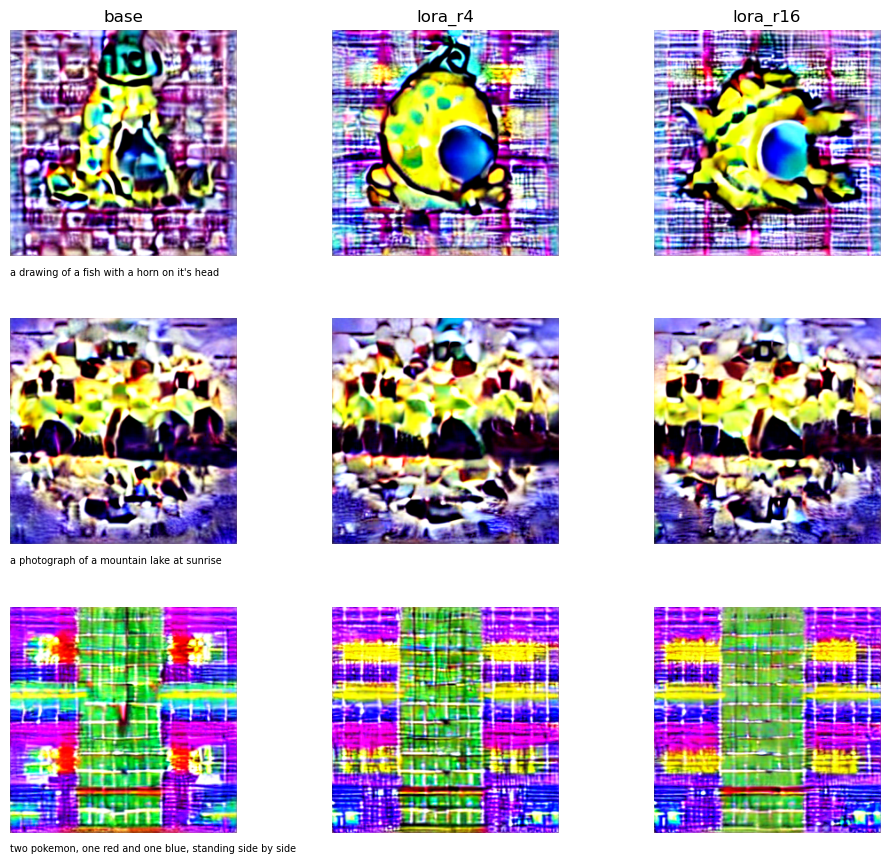

In [10]:
# Side-by-side grids: base | run 1 | run 2 (seed 0), up to 8 prompts
import matplotlib.pyplot as plt
models = ["base"] + [r["name"] for r in RUNS]
show = sel[:8]
fig, ax = plt.subplots(len(show), 3, figsize=(9, 3 * len(show)), squeeze=False)
for r, p in enumerate(show):
    for c, m in enumerate(models):
        ax[r][c].imshow(images[(m, p["id"], 0)]); ax[r][c].axis("off")
        if r == 0: ax[r][c].set_title(m)
    ax[r][0].text(0, -0.05, p["prompt"][:60], transform=ax[r][0].transAxes, fontsize=7, va="top")
plt.tight_layout(); plt.savefig(f"{OUT}/grid.png", dpi=110); plt.show()

## 2.4 Evaluation
Primary: KID (in-domain generations vs test images, lower is better, noisy at small n) and CLIP score.
Secondary: diversity = mean LPIPS between the two seeds of each prompt. Efficiency: GPU-hours and peak memory (table above).

In [11]:
from transformers import CLIPModel, CLIPProcessor
import lpips
from torchmetrics.image.kid import KernelInceptionDistance
clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DEV).eval()
cproc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
lp = lpips.LPIPS(net="alex").to(DEV)
to_t = transforms.Compose([transforms.ToTensor(), transforms.Normalize([0.5], [0.5])])
u8 = lambda ims: torch.stack([torch.from_numpy(np.array(i.resize((299, 299)))).permute(2, 0, 1) for i in ims])

def clip_score(m):
    sc = []
    for p in sel:
        for s in (0, 1):
            inp = cproc(text=[p["prompt"]], images=[images[(m, p["id"], s)]], return_tensors="pt", padding=True).to(DEV)
            with torch.no_grad(): o = clip(**inp)
            sc.append(float(o.logits_per_image / clip.logit_scale.exp()))
    return float(np.mean(sc))

def diversity(m):
    d = []
    for p in sel:
        a, b = (to_t(images[(m, p["id"], s)]).unsqueeze(0).to(DEV) for s in (0, 1))
        with torch.no_grad(): d.append(lp(a, b).item())
    return float(np.mean(d))

def kid(m):
    ids = [p["id"] for p in sel if p["type"] == "in-domain"]
    fake = [images[(m, i, s)] for i in ids for s in (0, 1)]; real = [im for im, _ in test]
    k = KernelInceptionDistance(subset_size=max(2, min(len(fake), len(real), 50)))
    k.update(u8(real), real=True); k.update(u8(fake), real=False)
    mu, sd = k.compute(); return float(mu), float(sd)

rows = []
for m in models:
    mu, sd = kid(m)
    rows.append({"model": m, "KID_mean": round(mu, 5), "KID_std": round(sd, 5), "CLIP": round(clip_score(m), 4), "LPIPS_diversity": round(diversity(m), 4)})
res = pd.DataFrame(rows)
eff = train_df.set_index("run")[["trainable_params", "gpu_hours", "peak_mem_gb"]]
res = res.merge(eff, left_on="model", right_index=True, how="left")
display(res); res.to_csv(f"{EVAL}/p2_results.csv", index=False)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
vision_model.embeddings.position_ids | UNEXPECTED |  | 
text_model.embeddings.position_ids   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


The image processor of type `CLIPImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]
Loading model from: /opt/anaconda3/lib/python3.13/site-packages/lpips/weights/v0.1/alex.pth


/opt/anaconda3/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


/Users/snehasingh/Desktop/Fall 2026 Lab 2/.venv/lib/python3.13/site-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)


/var/folders/g4/nd6wfspd3sx8dm7ps7vg9dn80000gn/T/ipykernel_81123/3570182964.py:16: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:837.)
  sc.append(float(o.logits_per_image / clip.logit_scale.exp()))


,model,KID_mean,KID_std,CLIP,LPIPS_diversity,trainable_params,gpu_hours,peak_mem_gb
0,base,0.17248,0.01294,0.2031,0.6991,NaN,NaN,NaN
1,lora_r4,0.23591,0.04474,0.2081,0.6929,797184.0,0.0010,5.42
2,lora_r16,0.19636,0.04697,0.2154,0.7112,3188736.0,0.0007,5.52


### Human evaluation (blinded, 25 pairs)
Final run vs base, left/right randomized. 3+ raters (both members + one outside the team) fill `winner` with L or R. Answer key is a separate file.

In [12]:
FINAL = RUNS[-1]["name"]   # update after reviewing results; justify in report
pairs = [(p["id"], s) for p in PROMPTS for s in (0, 1)]
pairs = [(i, s) for i, s in pairs if ("base", i, s) in images]
r = random.Random(SEED); r.shuffle(pairs); pairs = pairs[:N_PAIRS]; pairs.sort()   # random 25 of the 40, seed 266
r = random.Random(SEED + 1); rows_k, rows_r = [], []
os.makedirs(f"{OUT}/human_eval", exist_ok=True)
for n, (pid, s) in enumerate(pairs):
    base_left = r.random() < 0.5
    L, R = (("base", FINAL) if base_left else (FINAL, "base"))
    images[(L, pid, s)].save(f"{OUT}/human_eval/pair{n:02d}_L.png"); images[(R, pid, s)].save(f"{OUT}/human_eval/pair{n:02d}_R.png")
    rows_r.append({"pair": n, "prompt": next(p["prompt"] for p in PROMPTS if p["id"] == pid), "rater1": "", "rater2": "", "rater3": ""})
    rows_k.append({"pair": n, "left": L, "right": R})
pd.DataFrame(rows_r).to_csv(f"{EVAL}/p2_human_review.csv", index=False)       # raters fill with L or R
pd.DataFrame(rows_k).to_csv(f"{OUT}/human_eval/answer_key.csv", index=False)  # do not show raters
print(len(pairs), "pairs written")

3 pairs written


In [13]:
# After raters fill p2_human_review.csv (in the eval folder): win rate of the final run vs base
rev = pd.read_csv(f"{EVAL}/p2_human_review.csv"); key = pd.read_csv(f"{OUT}/human_eval/answer_key.csv").set_index("pair")
wins = tot = 0
for _, row in rev.iterrows():
    for c in ["rater1", "rater2", "rater3"]:
        v = row[c]
        if v in ("L", "R"):
            tot += 1; wins += (key.loc[row["pair"], "left" if v == "L" else "right"] == FINAL)
print({"votes": tot, "final_win_rate": round(wins / tot, 3) if tot else None})

{'votes': 0, 'final_win_rate': None}


### Safety (C4): NSFW filter and memorization check

In [14]:
# NSFW filter: SD safety checker run on every generated image
from diffusers.pipelines.stable_diffusion.safety_checker import StableDiffusionSafetyChecker
from transformers import CLIPImageProcessor
sc = StableDiffusionSafetyChecker.from_pretrained(MODEL, subfolder="safety_checker", variant="fp16").to(DEV).eval()
fe = CLIPImageProcessor.from_pretrained(MODEL, subfolder="feature_extractor")
flagged = 0
for k, im in images.items():
    inp = fe(im, return_tensors="pt").to(DEV)
    with torch.no_grad():
        _, f = sc(images=[np.array(im)], clip_input=inp.pixel_values.to(sc.dtype))
    flagged += int(f[0])
print({"images_checked": len(images), "flagged_nsfw": flagged})
del sc; _ = gc.collect()

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

StableDiffusionSafetyChecker LOAD REPORT from: stable-diffusion-v1-5/stable-diffusion-v1-5
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
vision_model.vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


{'images_checked': 18, 'flagged_nsfw': 5}


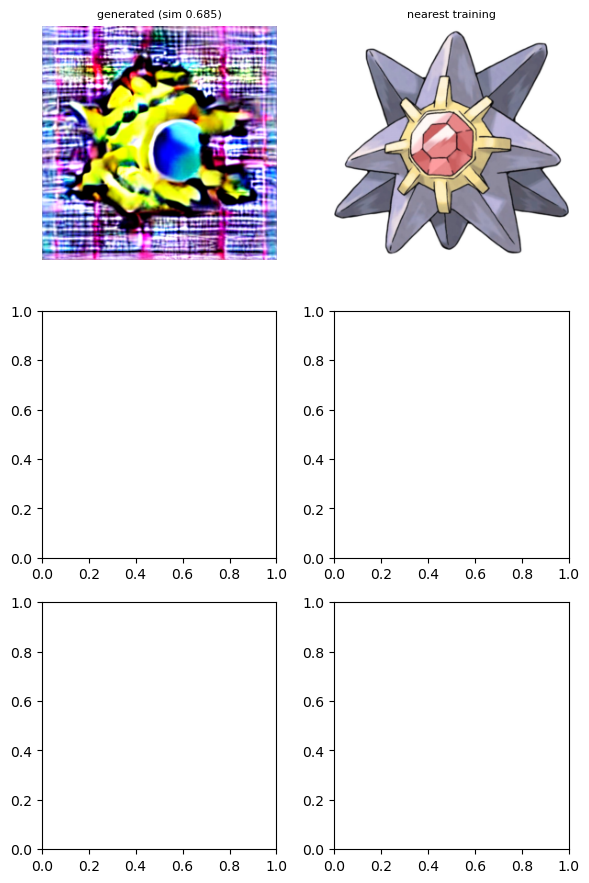

{'max_sim_per_prompt': [0.685]}
{'max_tile_rms_to_nearest_train': [0.531], 'note': 'RMS per tile (our normalization); values near/below ~0.15 would suggest a near-copy, higher means a new image'}


In [15]:
# Memorization: for 10 in-domain generations of the final run, nearest training image by CLIP cosine similarity; show 3 closest pairs
def cemb(ims, bs=32):
    out = []
    for i in range(0, len(ims), bs):
        inp = cproc(images=ims[i:i+bs], return_tensors="pt").to(DEV)
        with torch.no_grad(): e = clip.get_image_features(**inp)
        e = e if torch.is_tensor(e) else e.pooler_output
        out.append(torch.nn.functional.normalize(e, dim=-1).cpu())
    return torch.cat(out)
gen_ids = [p["id"] for p in sel if p["type"] == "in-domain"][:10]
gen_ims = [images[(FINAL, i, 0)] for i in gen_ids]
sim = cemb(gen_ims) @ cemb([im for im, _ in train]).T
best, arg = sim.max(dim=1)
top = best.argsort(descending=True)[:3].tolist()
fig, ax = plt.subplots(3, 2, figsize=(6, 9))
for r_, g in enumerate(top):
    ax[r_][0].imshow(gen_ims[g]); ax[r_][0].set_title(f"generated (sim {best[g]:.3f})", fontsize=8)
    ax[r_][1].imshow(train[arg[g]][0]); ax[r_][1].set_title("nearest training", fontsize=8)
    for a in ax[r_]: a.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT}/memorization.png", dpi=110); plt.show()
print({"max_sim_per_prompt": [round(float(v), 3) for v in best]})

# Carlini et al. 2023 also use a stricter tile test: split into 16 non-overlapping tiles and take the MAX
# per-tile distance between the two images; small (they use 0.15 on normalized l2) means a near-exact copy.
def tile_dist(a, b, g=4):
    A, B = np.asarray(a.resize((RES, RES)), dtype=np.float32) / 255, np.asarray(b.resize((RES, RES)), dtype=np.float32) / 255
    t = RES // g
    return max(float(np.sqrt(np.mean((A[i*t:(i+1)*t, j*t:(j+1)*t] - B[i*t:(i+1)*t, j*t:(j+1)*t]) ** 2))) for i in range(g) for j in range(g))
td = [tile_dist(gen_ims[g], train[arg[g]][0]) for g in range(len(gen_ims))]
print({"max_tile_rms_to_nearest_train": [round(v, 3) for v in td],
       "note": "RMS per tile (our normalization); values near/below ~0.15 would suggest a near-copy, higher means a new image"})

In [16]:
# Push all generated images to a HF dataset with prompt, seed and model metadata
if PUSH:
    from datasets import Dataset, Features, Value, Image as HFImage
    recs = [{"image": im, "model": m, "prompt_id": pid, "prompt": next(p["prompt"] for p in PROMPTS if p["id"] == pid), "seed": s}
            for (m, pid, s), im in images.items()]
    Dataset.from_list(recs).cast_column("image", HFImage()).push_to_hub(f"{HF_USER}/data266-lab2-p2-images")

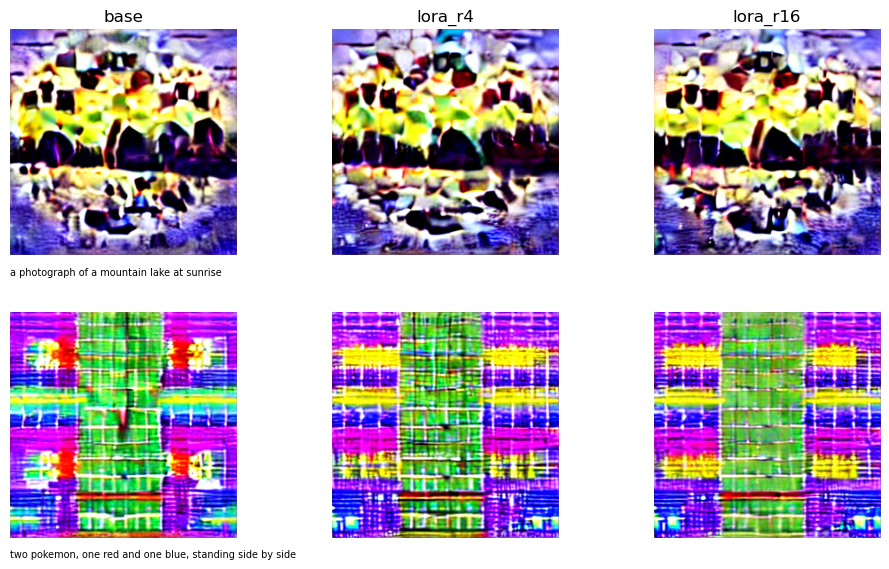

In [17]:
# Failure-mode candidates: out-of-domain and compositional prompts, base vs both runs (seed 0)
cand = [p for p in sel if p["type"] != "in-domain"]
if cand:
    fig, ax = plt.subplots(len(cand), 3, figsize=(9, 3 * len(cand)), squeeze=False)
    for r_, p in enumerate(cand):
        for c, m in enumerate(models):
            ax[r_][c].imshow(images[(m, p["id"], 0)]); ax[r_][c].axis("off")
            if r_ == 0: ax[r_][c].set_title(m)
        ax[r_][0].text(0, -0.05, p["prompt"][:60], transform=ax[r_][0].transAxes, fontsize=7, va="top")
    plt.tight_layout(); plt.savefig(f"{OUT}/failure_candidates.png", dpi=100); plt.show()

In [18]:
# Package everything and (on Colab) download it. Also pushed to Drive already.
import shutil
total_h = sum(r["gpu_hours"] for r in train_rows)
print({"training_gpu_hours_total": round(total_h, 3), "outputs": OUT, "eval": EVAL})
if not SMOKE:
    shutil.make_archive("/content/p2_outputs" if IN_COLAB else "p2_outputs", "zip", OUT)
    if IN_COLAB:
        from google.colab import files; files.download("/content/p2_outputs.zip")

{'training_gpu_hours_total': 0.002, 'outputs': 'outputs/p2_smoke', 'eval': 'outputs/p2_smoke/eval'}


## Failure modes and final model choice
Fill after the real run: two failure modes with example images (e.g. ignores the prompt on out-of-domain,
repeated or overfit outputs), and which run is final and why (use the results table, human win rate, memorization).